In [5]:
import numpy as np

In [6]:
# We assume these vector are token embeddings + positional embeddings 
inputs_attention = np.array(
    [[0.42, 0.2, 0.14, 0.01], # I
    [0.31, 0.53, 0.66, 0.41], # LOVE
    [0.89, 0.52, 0.26, 0.13], # BRANDO
    [0.02, 0.95, 0.98, 0.37], # CODE
    [0.10, 0.16, 0.05, 0.08]] # VIDEOS
    
)

### 1.1.1 Self-Attention Calculations for a Single Embedding

Use **BRANDO**, the third embedding, as the query.

1. **Calculate attention scores:** take the dot product of each embedding with the query.
2. **Calculate attention weights:** apply softmax to the scores.
3. **Calculate the context vector:** take the weighted sum of all embeddings.

The calculations are:

$$
s = Xq
$$

$$
w = \mathrm{softmax}(s)
$$

$$
c = w^{T}X
$$

Here, $X$ contains the five word embeddings and $q$ is the embedding for **BRANDO**. The embeddings serve directly as queries, keys, and values, without learned projections or score scaling.

The diagram below shows the calculated values, rounded for display.


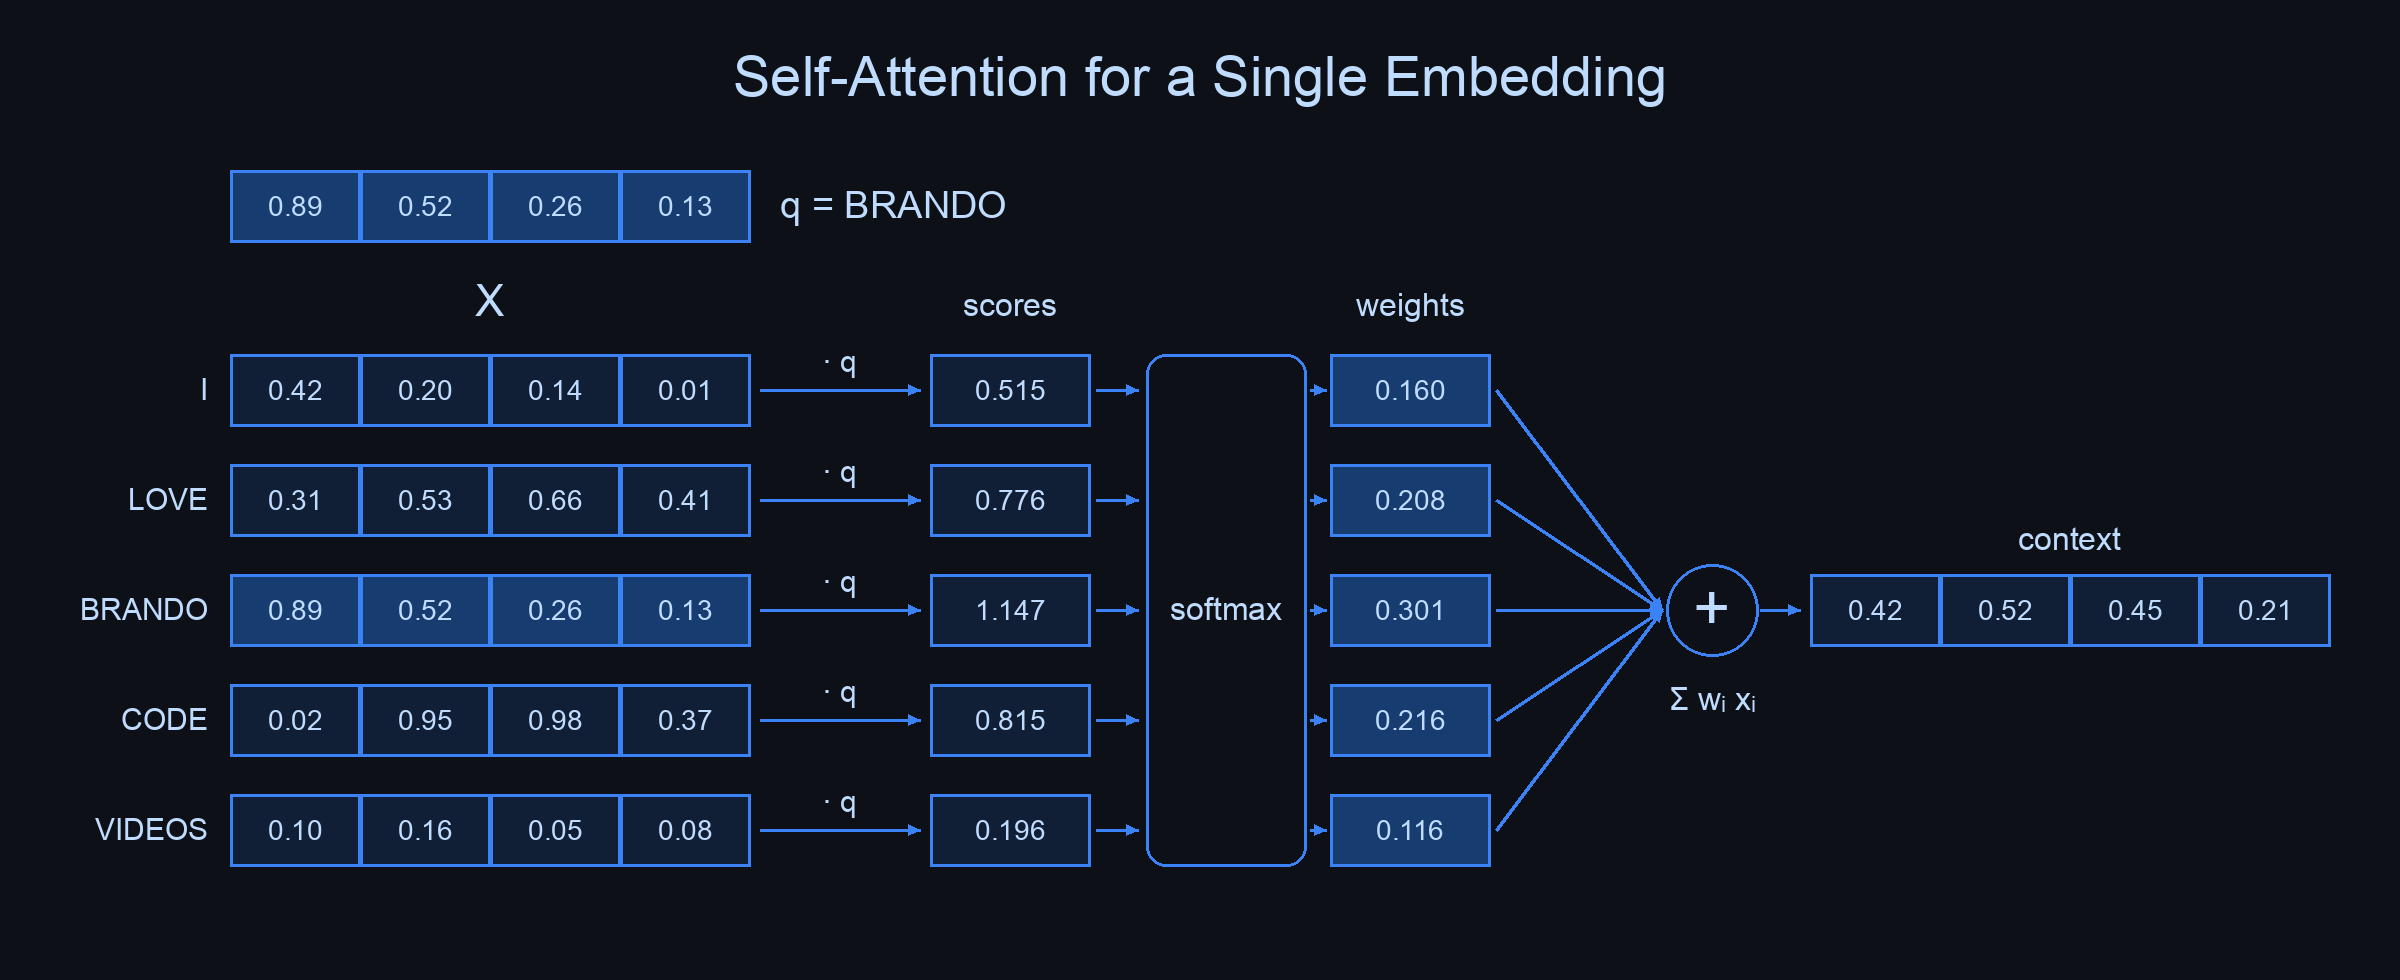


In [7]:
# Calculate a single context vector
query_vector = inputs_attention[2] # BRANDO (I could have chosen any though)
query_vector

array([0.89, 0.52, 0.26, 0.13])

In [8]:
# Calculate all dot product
attention_scores = []

for vec in inputs_attention:
    print(f"Dot product between {query_vector} and {vec}: {query_vector.dot(vec)}")
    attention_scores.append(query_vector.dot(vec))

attention_scores = np.array(attention_scores)
attention_scores

Dot product between [0.89 0.52 0.26 0.13] and [0.42 0.2  0.14 0.01]: 0.5155
Dot product between [0.89 0.52 0.26 0.13] and [0.31 0.53 0.66 0.41]: 0.7764
Dot product between [0.89 0.52 0.26 0.13] and [0.89 0.52 0.26 0.13]: 1.147
Dot product between [0.89 0.52 0.26 0.13] and [0.02 0.95 0.98 0.37]: 0.8147000000000001
Dot product between [0.89 0.52 0.26 0.13] and [0.1  0.16 0.05 0.08]: 0.19560000000000002


array([0.5155, 0.7764, 1.147 , 0.8147, 0.1956])

In [9]:
# Numerically stable softmax as explained before
def softmax(x, axis=-1):
    max_logit = np.max(x, axis = -1, keepdims= True)
    return np.exp(x - max_logit) / np.sum(np.exp(x - max_logit), axis=-1, keepdims = True)

In [10]:
# Apply the softmax function to normalize all the attention scores
attention_weights = softmax(attention_scores)
print(f"Attention Weights: {attention_weights}")
print(f"Sum of all attention weights: {np.sum(attention_weights)}")


Attention Weights: [0.15990974 0.20757848 0.30069892 0.21568295 0.11612991]
Sum of all attention weights: 0.9999999999999998


In [11]:
print(attention_weights[0] * inputs_attention[0] +
      attention_weights[1] * inputs_attention[1] +
      attention_weights[2] * inputs_attention[2] +
      attention_weights[3] * inputs_attention[3] +
      attention_weights[4] * inputs_attention[4])

[0.41506011 0.52184157 0.45474667 0.21489022]


In [12]:
scores = inputs_attention.dot(inputs_attention.T)
scores

array([[0.2361, 0.3327, 0.5155, 0.3393, 0.0818],
       [0.3327, 0.9807, 0.7764, 1.3082, 0.1816],
       [0.5155, 0.7764, 1.147 , 0.8147, 0.1956],
       [0.3393, 1.3082, 0.8147, 2.0002, 0.2326],
       [0.0818, 0.1816, 0.1956, 0.2326, 0.0445]])

### Self-attention for all words

Compute scores with $XX^T$, apply softmax to each row to obtain the attention weights, then multiply the weights by $X$ to obtain the context vectors.

.The code above uses **BRANDO** and `0.20` in the second component, so its numerical results differ slightly.

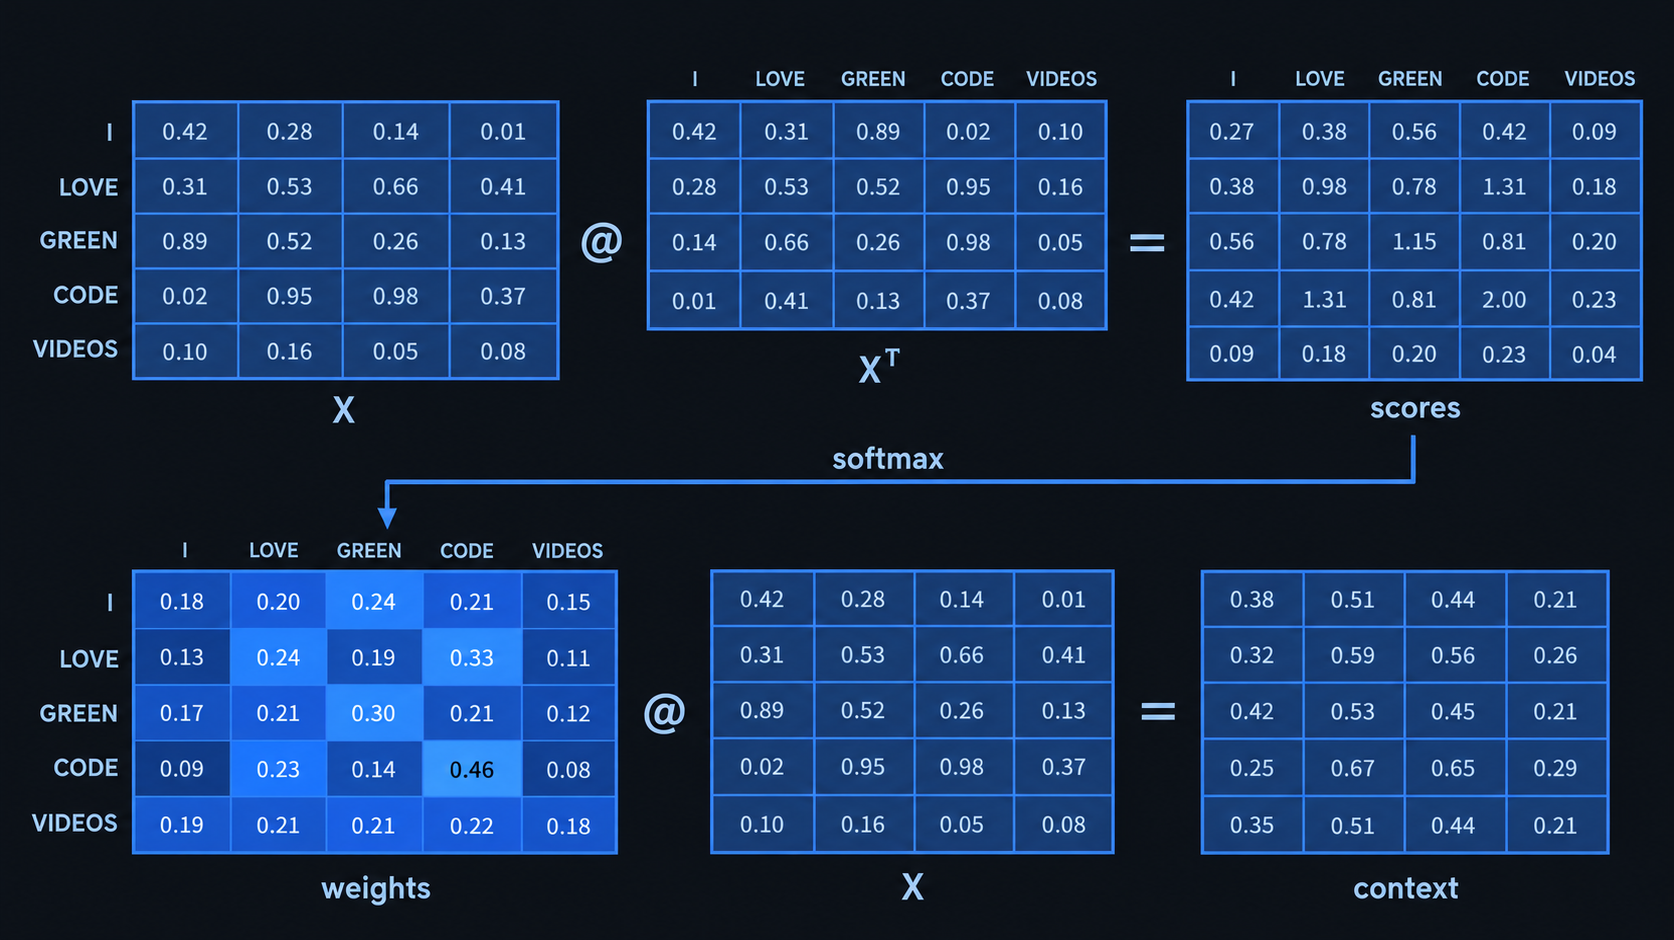


In [13]:
# Attention Matrix for all Queries so XX^T
all_attention_scores = inputs_attention.dot(inputs_attention.T)
all_attention_scores

array([[0.2361, 0.3327, 0.5155, 0.3393, 0.0818],
       [0.3327, 0.9807, 0.7764, 1.3082, 0.1816],
       [0.5155, 0.7764, 1.147 , 0.8147, 0.1956],
       [0.3393, 1.3082, 0.8147, 2.0002, 0.2326],
       [0.0818, 0.1816, 0.1956, 0.2326, 0.0445]])

In [14]:
all_attention_weights = softmax(all_attention_scores)
all_attention_weights

array([[0.18554652, 0.2043646 , 0.24535488, 0.20571787, 0.15901613],
       [0.12527512, 0.23949014, 0.19523662, 0.33229138, 0.10770675],
       [0.15990974, 0.20757848, 0.30069892, 0.21568295, 0.11612991],
       [0.08766898, 0.23101164, 0.14102936, 0.46149356, 0.07879646],
       [0.18685899, 0.20646982, 0.20938073, 0.21727292, 0.18001754]])

In [15]:
all_context_vectors = all_attention_weights @ inputs_attention
all_context_vectors

array([[0.37966438, 0.49388163, 0.43420373, 0.20637799],
       [0.31803458, 0.58641773, 0.55739442, 0.25638882],
       [0.41506011, 0.52184157, 0.45474667, 0.21489022],
       [0.25106023, 0.66433155, 0.65761248, 0.29098161],
       [0.35118248, 0.49089086, 0.43879767, 0.2085331 ]])

## 1.2 Self-Attention with Trainable Weights

In the previous section, each embedding played three roles at once: the **query**, the **key**, and the **value**. We used the same input matrix $X$ for all three roles.

Now we create three different representations of each embedding using trainable matrices:

- **Query ($Q$):** what a token is looking for in other tokens.
- **Key ($K$):** what a token offers for comparison with a query.
- **Value ($V$):** the information a token contributes to the final context vector.

### The trainable matrices

$$
Q = XW_q, \qquad K = XW_k, \qquad V = XW_v
$$

The entries of $W_q$, $W_k$, and $W_v$ are model parameters. They are usually initialized randomly and updated during training: backpropagation computes how they affect the loss, and an optimizer adjusts them to reduce that loss. Within this attention head, the same three matrices are applied to every token.

**Trainable weights and attention weights are different:** $W_q$, $W_k$, and $W_v$ are learned parameters stored in the model. The attention weights are calculated from the current queries and keys, so they change with the input. They are not a separate matrix of independently learned parameters.

### From embeddings to context vectors

1. Project the embeddings to obtain $Q$, $K$, and $V$.
2. Compare every query with every key using $QK^T$.
3. Divide the scores by $\sqrt{d_k}$, where $d_k$ is the number of components in each key/query vector. This controls score magnitudes as that dimension grows.
4. Apply softmax **across each row** to obtain attention weights that sum to one for each query.
5. Multiply these weights by $V$ to obtain a context vector for each token.

$$
A = \mathrm{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)
$$

$$
C = AV
$$

Equivalently:

$$
\mathrm{Attention}(Q,K,V) = \mathrm{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V
$$

### Shapes in our example

Our input $X$ has shape $(5,4)$: five tokens, each with four embedding components. If we choose $d_k=d_v=4$, each trainable matrix has shape $(4,4)$. Then $Q$, $K$, and $V$ each have shape $(5,4)$, the scores and attention weights have shape $(5,5)$, and the context matrix has shape $(5,4)$.

For example, the context vector for **BRANDO** is a weighted sum of all five **value vectors**. The weights come from comparing BRANDO's query with every token's key.


### Diagram: self-attention with trainable weights

1. **Project the embeddings:** multiply $X$ by the three trainable matrices to obtain $Q=XW_q$, $K=XW_k$, and $V=XW_v$.
2. **Calculate scores:** $QK^T$ compares each token's query with every token's key.
3. **Calculate attention weights:** divide the scores by $\sqrt{d_k}$ and apply softmax across each row.
4. **Calculate context vectors:** multiply the attention weights by $V$. Each output row is a weighted sum of the value vectors.

$$
C = \mathrm{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V
$$

The model learns $W_q$, $W_k$, and $W_v$ during training. The attention weights are computed from the current input; they are different from those trainable parameters.

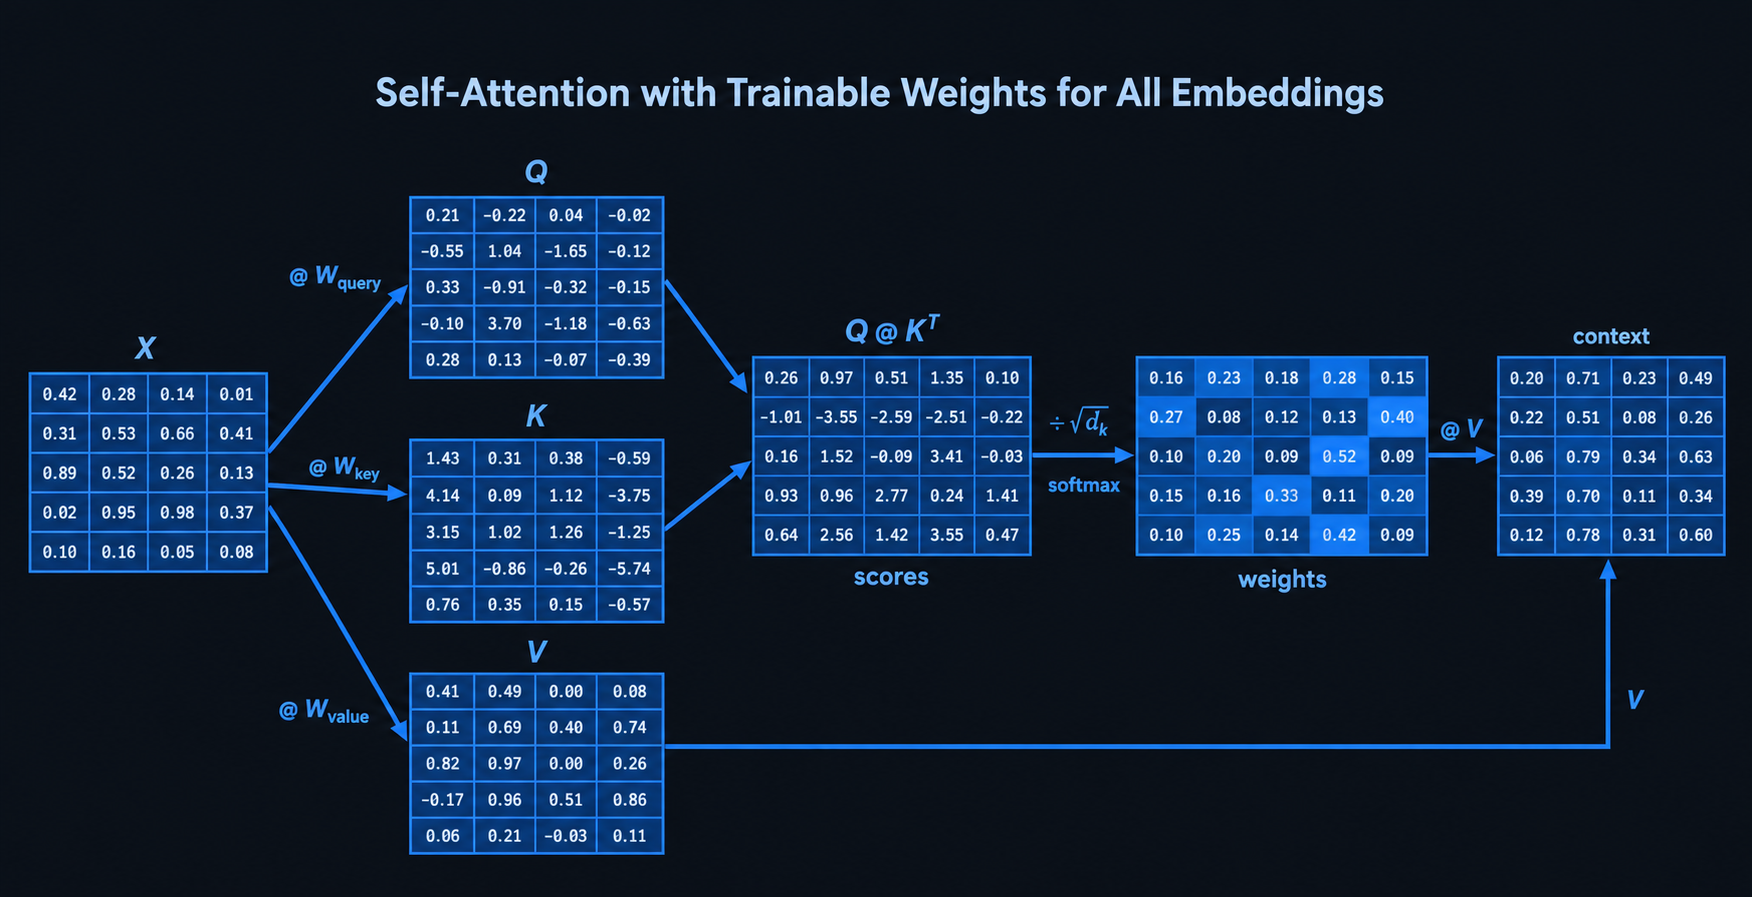

The diagram uses its own numerical example; its values may differ from the notebook's calculations.


In [16]:
d_in = inputs_attention.shape[1]
d_out = d_in

w_query = np.array([
    [ 0.10, -0.20,  0.30,  0.40],
    [ 0.50,  0.60, -0.10,  0.20],
    [-0.30,  0.40,  0.50, -0.20],
    [ 0.20, -0.10,  0.60,  0.30],
])

w_key = np.array([
    [ 0.30,  0.10, -0.20,  0.50],
    [-0.40,  0.60,  0.20,  0.10],
    [ 0.50, -0.30,  0.40,  0.20],
    [ 0.10,  0.20, -0.50,  0.60],
])

w_value = np.array([
    [ 0.20,  0.40,  0.10, -0.30],
    [ 0.60, -0.20,  0.30,  0.50],
    [-0.10,  0.50,  0.40,  0.20],
    [ 0.30,  0.10, -0.20,  0.60],
])

In [17]:
# The query now comes from projecting the embedding with w_QUERY
query_vector = inputs_attention[2] @ w_query
print(f"Embedding: {inputs_attention[2]} -> Query: {query_vector}")



Embedding: [0.89 0.52 0.26 0.13] -> Query: [0.297 0.225 0.423 0.447]


In [18]:
keys = inputs_attention @ w_key
values = inputs_attention @ w_value

print(f"Keys:\n{keys}")
print(f"Value:\n{values}")

Keys:
[[ 0.117  0.122  0.007  0.264]
 [ 0.252  0.233  0.103  0.586]
 [ 0.202  0.349 -0.035  0.627]
 [ 0.153  0.352  0.393  0.523]
 [-0.001  0.107 -0.008  0.124]]
Value:
[[0.193 0.199 0.156 0.008]
 [0.437 0.389 0.372 0.55 ]
 [0.503 0.395 0.323 0.123]
 [0.587 0.345 0.605 0.887]
 [0.135 0.041 0.062 0.108]]


In [19]:
attention_scores = []

for key_vector in keys:
    print(f"Dot product between  {query_vector} and {key_vector}: {query_vector.dot(key_vector)}")
    attention_scores.append(query_vector @ key_vector)

attention_scores = np.array(attention_scores)
attention_scores


Dot product between  [0.297 0.225 0.423 0.447] and [0.117 0.122 0.007 0.264]: 0.18316800000000003
Dot product between  [0.297 0.225 0.423 0.447] and [0.252 0.233 0.103 0.586]: 0.43278000000000005
Dot product between  [0.297 0.225 0.423 0.447] and [ 0.202  0.349 -0.035  0.627]: 0.40398300000000004
Dot product between  [0.297 0.225 0.423 0.447] and [0.153 0.352 0.393 0.523]: 0.524661
Dot product between  [0.297 0.225 0.423 0.447] and [-0.001  0.107 -0.008  0.124]: 0.075822


array([0.183168, 0.43278 , 0.403983, 0.524661, 0.075822])

In [20]:
# Scale and apply the softmax function to normalize all the attention scores
d_k = keys.shape[-1]

attention_weights = softmax(attention_scores / d_k**0.5)
print(f"Attention Weights: {attention_weights}")
print(f"Sum of all attention weights: {np.sum(attention_weights)}")




Attention Weights: [0.18574953 0.21044096 0.20743264 0.22033424 0.17604263]
Sum of all attention weights: 1.0


In [21]:
# The context vector is now a weighted sum of the VALUES (not of the raw embeddings)
context_vector = np.zeros(d_out)

for idx, weight in enumerate(attention_weights):
    context_vector += weight * values[idx]

context_vector

array([0.38525293, 0.28399464, 0.31847857, 0.35719181])

In [22]:
queries = inputs_attention @ w_query
keys = inputs_attention @ w_key
values = inputs_attention @ w_value

print(f"Inputs: {inputs_attention.shape} -> Queries: {queries.shape}, Keys: {keys.shape}, Values: {values.shape}")

Inputs: (5, 4) -> Queries: (5, 4), Keys: (5, 4), Values: (5, 4)


In [23]:
all_attention_scores = queries @ keys.T
all_attention_scores

array([[0.072622, 0.172891, 0.160734, 0.214873, 0.030871],
       [0.142154, 0.349921, 0.320538, 0.553819, 0.073549],
       [0.183168, 0.43278 , 0.403983, 0.524661, 0.075822],
       [0.176624, 0.409744, 0.422389, 0.667451, 0.107318],
       [0.044696, 0.102793, 0.099971, 0.124068, 0.019293]])

In [24]:
all_attention_weights = softmax(all_attention_scores / d_k**0.5)
all_attention_weights

array([[0.19419323, 0.20417718, 0.20293986, 0.20850837, 0.19018137],
       [0.18526793, 0.20554943, 0.20255167, 0.22761043, 0.17902054],
       [0.18574953, 0.21044096, 0.20743264, 0.22033424, 0.17604263],
       [0.18186888, 0.20435241, 0.20564852, 0.23245566, 0.17567453],
       [0.1966429 , 0.20243886, 0.20215342, 0.20460379, 0.19416104]])

In [25]:
all_context_vectors = all_attention_weights @ values
all_context_vectors

array([[0.37685237, 0.27796344, 0.30973644, 0.34429911],
       [0.3852404 , 0.2827004 , 0.31959396, 0.36067286],
       [0.38525293, 0.28399464, 0.31847857, 0.35719181],
       [0.38801144, 0.28431602, 0.32234261, 0.36430456],
       [0.37441519, 0.27628016, 0.30710238, 0.34023234]])

In [26]:
# Row 2 Brando is the same context vector we calculate by hand
np.allclose(all_context_vectors[2], context_vector)

True

## 1.3 Causal Attention

Each token can attend to **itself and earlier tokens**, but cannot look ahead. For example, **BRANDO** can use I, LOVE, and BRANDO, but cannot use CODE or VIDEOS.

This blue diagram uses the exact `inputs_attention`, `w_query`, `w_key`, and `w_value` defined above. The values matrix contains the **projected inputs**, not the raw embeddings.

$$M_{ij}=\begin{cases}0 & j\le i\\-\infty & j>i\end{cases},\qquad A=\mathrm{softmax}\!\left(\frac{QK^T+M}{\sqrt{d_k}}\right),\qquad C=AV$$

Here $d_k=4$, so the scale divisor is $2$. Softmax is applied across each row, and future positions have exactly zero weight. Run the cells below again after changing your input data to update the calculations and diagram.


In [27]:
# Use the same input embeddings and projection matrices defined above.
causal_tokens = ["I", "LOVE", "BRANDO", "CODE", "VIDEOS"]
causal_queries = inputs_attention @ w_query
causal_keys = inputs_attention @ w_key
causal_values = inputs_attention @ w_value
causal_scores = causal_queries @ causal_keys.T
causal_d_k = causal_keys.shape[-1]

# Rows are queries; columns are keys. Block every future token (column > row).
future_tokens = np.triu(np.ones(causal_scores.shape, dtype=bool), k=1)
causal_mask = np.where(future_tokens, -np.inf, 0.0)
causal_masked_scores = causal_scores + causal_mask
causal_weights = softmax(causal_masked_scores / np.sqrt(causal_d_k))
causal_context_vectors = causal_weights @ causal_values

assert np.allclose(causal_weights.sum(axis=1), 1.0)
assert np.all(causal_weights[future_tokens] == 0.0)
assert np.allclose(causal_context_vectors[0], causal_values[0])
print("Causal context vectors (rows: I, LOVE, BRANDO, CODE, VIDEOS):")
print(causal_context_vectors)


Causal context vectors (rows: I, LOVE, BRANDO, CODE, VIDEOS):
[[0.193      0.199      0.156      0.008     ]
 [0.3213312  0.29893003 0.26960467 0.29306357]
 [0.38459589 0.33259425 0.28869289 0.23647659]
 [0.44193148 0.33616984 0.37782502 0.41892642]
 [0.37441519 0.27628016 0.30710238 0.34023234]]


![Causal attention: scores + mask, softmax, then weights @ values](causal-attention.png)

In [45]:
num_tokens = inputs_attention.shape[0]

# -nf above the diagonal, 0 elsewhere (adding - changes nothing)
mask = np.triu(np.full((num_tokens, num_tokens), -np.inf), k = 1)
mask

array([[  0., -inf, -inf, -inf, -inf],
       [  0.,   0., -inf, -inf, -inf],
       [  0.,   0.,   0., -inf, -inf],
       [  0.,   0.,   0.,   0., -inf],
       [  0.,   0.,   0.,   0.,   0.]])

In [46]:
masked_attention_scores = all_attention_scores + mask
masked_attention_scores

array([[0.072622,     -inf,     -inf,     -inf,     -inf],
       [0.142154, 0.349921,     -inf,     -inf,     -inf],
       [0.183168, 0.43278 , 0.403983,     -inf,     -inf],
       [0.176624, 0.409744, 0.422389, 0.667451,     -inf],
       [0.044696, 0.102793, 0.099971, 0.124068, 0.019293]])

In [30]:
masked_attention_weights = softmax(masked_attention_scores / d_k**0.5)
masked_attention_weights

array([[1.        , 0.        , 0.        , 0.        , 0.        ],
       [0.47405246, 0.52594754, 0.        , 0.        , 0.        ],
       [0.30772434, 0.34862972, 0.34364594, 0.        , 0.        ],
       [0.22062752, 0.24790258, 0.24947491, 0.281995  , 0.        ],
       [0.1966429 , 0.20243886, 0.20215342, 0.20460379, 0.19416104]])

In [31]:
masked_context_vectors = masked_attention_weights @ values
masked_context_vectors

array([[0.193     , 0.199     , 0.156     , 0.008     ],
       [0.3213312 , 0.29893003, 0.26960467, 0.29306357],
       [0.38459589, 0.33259425, 0.28869289, 0.23647659],
       [0.44193148, 0.33616984, 0.37782502, 0.41892642],
       [0.37441519, 0.27628016, 0.30710238, 0.34023234]])

In [47]:
def causal_attention(x, W_query, W_key, W_value):
    query_matrix = x @ W_query
    key_matrix = x @ W_key
    value_matrix = x @ W_value

    num_tokens = x.shape[0]
    mask = np.triu(np.full((num_tokens, num_tokens), -np.inf), k=1)

    attention_scores = query_matrix @ key_matrix.T + mask
    attention_weights = softmax(attention_scores / key_matrix.shape[-1]**0.5)

    return attention_weights @ value_matrix

np.allclose(
    causal_attention(inputs_attention, w_query, w_key, w_value),
    masked_context_vectors
)

True

## 1.4 Multi-Head Attention — Slow Way

Run a **list of independent causal-attention heads, one after another**. Each head sees the full input **I LOVE BRANDO CODE VIDEOS**, but has its own query, key, and value projections and computes its own attention weights.

For this example, split your existing four-column projection matrices into two separate two-column matrices: **head 0 uses columns 0–1; head 1 uses columns 2–3**. Each head's projection matrices have shape $(4,2)$ and each head produces a $(5,2)$ output. These are illustrative parameter values, not weights trained in this notebook.

For each head $h$:
$$H_h=\mathrm{softmax}\left(\frac{(XW_{q,h})(XW_{k,h})^T+M}{\sqrt{2}}\right)(XW_{v,h})$$

Concatenate the outputs **along the feature axis**, keeping the five token rows, then mix the four features with an output projection:
$$H=\mathrm{concat}(H_0,H_1),\qquad Y=HW_{out}$$

The explicit $W_{out}$ below is a new illustrative matrix matching the reference's output projection. Each head scales by $\sqrt{2}$, so splitting the projections produces different attention weights from the earlier single four-dimensional head. “Slow” refers to the Python loop over heads; optimized implementations calculate heads together.


In [33]:
# Shape: (2 heads, 4 input features, 2 features per head).
# Index 0 selects Head 0; index 1 selects Head 1.
W_query_heads = np.array([
    [  # Head 0
        [ 0.10, -0.20],
        [ 0.50,  0.60],
        [-0.30,  0.40],
        [ 0.20, -0.10],
    ],
    [  # Head 1
        [ 0.30,  0.40],
        [-0.10,  0.20],
        [ 0.50, -0.20],
        [ 0.60,  0.30],
    ],
])

W_key_heads = np.array([
    [  # Head 0
        [ 0.30,  0.10],
        [-0.40,  0.60],
        [ 0.50, -0.30],
        [ 0.10,  0.20],
    ],
    [  # Head 1
        [-0.20,  0.50],
        [ 0.20,  0.10],
        [ 0.40,  0.20],
        [-0.50,  0.60],
    ],
])

W_value_heads = np.array([
    [  # Head 0
        [ 0.20,  0.40],
        [ 0.60, -0.20],
        [-0.10,  0.50],
        [ 0.30,  0.10],
    ],
    [  # Head 1
        [ 0.10, -0.30],
        [ 0.30,  0.50],
        [ 0.40,  0.20],
        [-0.20,  0.60],
    ],
])

# Shape: (4 concatenated head features, 4 output features).
W_out = np.array([
    [1.0, 0.0, 0.5, 0.0],
    [0.0, 1.0, 0.0, 0.5],
    [0.5, 0.0, 1.0, 0.0],
    [0.0, 0.5, 0.0, 1.0],
])

mha_tokens = ["I", "LOVE", "BRANDO", "CODE", "VIDEOS"]
mha_heads = list(zip(W_query_heads, W_key_heads, W_value_heads))

def multi_head_attention_slow(x, heads, w_out):
    head_outputs = []
    for w_q_head, w_k_head, w_v_head in heads:
        # Each call computes its own Q, K, V, causal mask, and softmax.
        head_output = causal_attention(x, w_q_head, w_k_head, w_v_head)
        head_outputs.append(head_output)
    concatenated = np.concatenate(head_outputs, axis=-1)
    output = concatenated @ w_out
    return output, head_outputs, concatenated

mha_output, mha_head_outputs, mha_concatenated = multi_head_attention_slow(
    inputs_attention, mha_heads, W_out
)
for head_index, head_output in enumerate(mha_head_outputs):
    print(f"Head {head_index} output ({head_output.shape}):\n{head_output}\n")
print(f"Concatenated ({mha_concatenated.shape}):\n{mha_concatenated}\n")
print(f"Final output ({mha_output.shape}):\n{mha_output}")


Head 0 output ((5, 2)):
[[0.193      0.199     ]
 [0.31834067 0.29660135]
 [0.38080714 0.3298009 ]
 [0.43904298 0.33630925]
 [0.37283883 0.27526301]]

Head 1 output ((5, 2)):
[[0.156      0.008     ]
 [0.26897175 0.29147541]
 [0.28876185 0.2374203 ]
 [0.37583259 0.41817092]
 [0.30686196 0.34026904]]

Concatenated ((5, 4)):
[[0.193      0.199      0.156      0.008     ]
 [0.31834067 0.29660135 0.26897175 0.29147541]
 [0.38080714 0.3298009  0.28876185 0.2374203 ]
 [0.43904298 0.33630925 0.37583259 0.41817092]
 [0.37283883 0.27526301 0.30686196 0.34026904]]

Final output ((5, 4)):
[[0.271      0.203      0.2525     0.1075    ]
 [0.45282655 0.44233905 0.42814209 0.43977609]
 [0.52518806 0.44851105 0.47916542 0.40232075]
 [0.62695928 0.54539471 0.59535408 0.58632554]
 [0.52626981 0.44539753 0.49328138 0.47790054]]


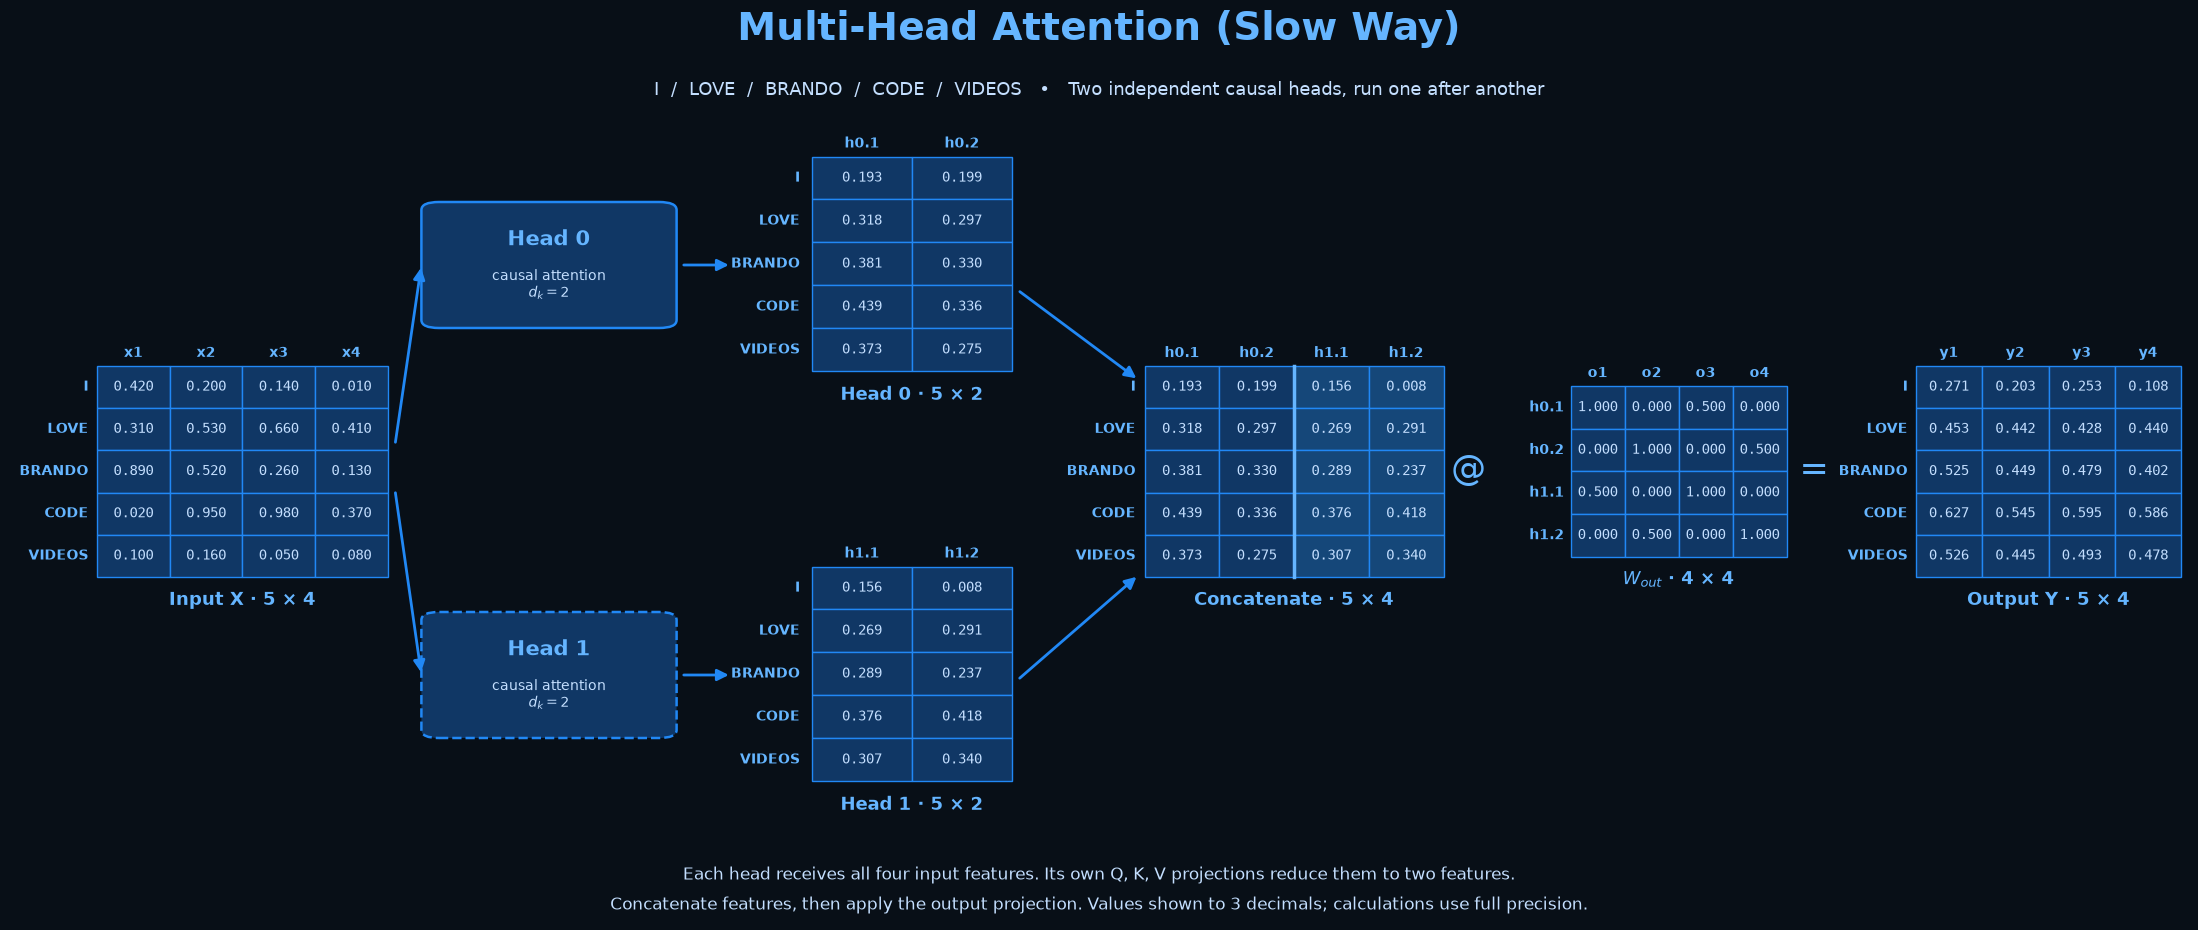

In [48]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, FancyBboxPatch, FancyArrowPatch

mha_fig = plt.figure(figsize=(22, 10), facecolor="#080f17")
mha_blue, mha_ink, mha_edge = "#65b5ff", "#c4dfff", "#2188f5"
mha_fig.text(0.5, 0.94, "Multi-Head Attention (Slow Way)", ha="center",
             color=mha_blue, fontsize=28, weight="bold")
mha_fig.text(0.5, 0.885, "I  /  LOVE  /  BRANDO  /  CODE  /  VIDEOS   •   Two independent causal heads, run one after another",
             ha="center", color=mha_ink, fontsize=13)

def mha_table(data, rect, title, columns, row_labels, split=False):
    ax = mha_fig.add_axes(rect)
    rows, cols = data.shape
    ax.set_xlim(-1.2, cols + 0.1)
    ax.set_ylim(rows + 0.9, -0.85)
    ax.axis("off")
    for j, label in enumerate(columns):
        ax.text(j + 0.5, -0.3, label, ha="center", va="center", fontsize=10,
                color=mha_blue, weight="bold")
    for i, label in enumerate(row_labels):
        ax.text(-0.12, i + 0.5, label, ha="right", va="center", fontsize=10,
                color=mha_blue, weight="bold")
        for j in range(cols):
            fill = "#154779" if split and j >= 2 else "#103765"
            ax.add_patch(Rectangle((j,i), 1, 1, facecolor=fill,
                                   edgecolor=mha_edge, linewidth=1))
            ax.text(j+0.5,i+0.5,f"{data[i,j]:.3f}",ha="center",va="center",
                    color=mha_ink, fontsize=10, family="monospace")
    if split:
        ax.plot([2,2],[0,rows], color=mha_blue, lw=2.5)
    ax.text(cols/2,rows+0.55,title,ha="center",va="center",
            color=mha_blue,fontsize=13,weight="bold")

def mha_arrow(start, end):
    mha_fig.add_artist(FancyArrowPatch(start,end,transform=mha_fig.transFigure,
                       arrowstyle="-|>",mutation_scale=17,linewidth=2,color=mha_edge))

def mha_box(rect, head):
    x,y,w,h=rect
    mha_fig.add_artist(FancyBboxPatch((x,y),w,h,transform=mha_fig.transFigure,
                      boxstyle="round,pad=0.008",facecolor="#103765",
                      edgecolor=mha_edge,linewidth=1.8,linestyle="--" if head else "-"))
    mha_fig.text(x+w/2,y+h*0.68,f"Head {head}",ha="center",color=mha_blue,
                 fontsize=15,weight="bold")
    mha_fig.text(x+w/2,y+h*0.32,"causal attention\n"+r"$d_k=2$",ha="center",
                 va="center",color=mha_ink,fontsize=10)

mha_table(inputs_attention,[0.005,0.365,0.175,0.285],"Input X · 5 × 4",
          ["x1","x2","x3","x4"],mha_tokens)
mha_box((0.20,0.66,0.10,0.11),0)
mha_box((0.20,0.25,0.10,0.11),1)
mha_table(mha_head_outputs[0],[0.315,0.57,0.15,0.29],"Head 0 · 5 × 2",["h0.1","h0.2"],mha_tokens)
mha_table(mha_head_outputs[1],[0.315,0.16,0.15,0.29],"Head 1 · 5 × 2",["h1.1","h1.2"],mha_tokens)
mha_table(mha_concatenated,[0.48,0.365,0.18,0.285],"Concatenate · 5 × 4",
          ["h0.1","h0.2","h1.1","h1.2"],mha_tokens,split=True)
mha_table(W_out,[0.685,0.385,0.13,0.245],r"$W_{out}$ · 4 × 4",
          ["o1","o2","o3","o4"],["h0.1","h0.2","h1.1","h1.2"])
mha_table(mha_output,[0.835,0.365,0.16,0.285],"Output Y · 5 × 4",
          ["y1","y2","y3","y4"],mha_tokens)
mha_arrow((0.18,0.535),(0.192,0.715))
mha_arrow((0.18,0.49),(0.192,0.305))
mha_arrow((0.31,0.715),(0.333,0.715))
mha_arrow((0.31,0.305),(0.333,0.305))
mha_arrow((0.463,0.69),(0.518,0.60))
mha_arrow((0.463,0.30),(0.518,0.405))
mha_fig.text(0.668,0.50,"@",ha="center",color=mha_blue,fontsize=25)
mha_fig.text(0.825,0.50,"=",ha="center",color=mha_blue,fontsize=25)
mha_fig.text(0.5,0.09,"Each head receives all four input features. Its own Q, K, V projections reduce them to two features.\n"
             "Concatenate features, then apply the output projection. Values shown to 3 decimals; calculations use full precision.",
             ha="center",va="center",color=mha_ink,fontsize=12,linespacing=1.8)
plt.show()


In [35]:

W_query_heads = np.array([
    [  # Head 0
        [ 0.10, -0.20],
        [ 0.50,  0.60],
        [-0.30,  0.40],
        [ 0.20, -0.10],
    ],
    [  # Head 1
        [ 0.30,  0.40],
        [-0.10,  0.20],
        [ 0.50, -0.20],
        [ 0.60,  0.30],
    ],
])

W_key_heads = np.array([
    [  # Head 0
        [ 0.30,  0.10],
        [-0.40,  0.60],
        [ 0.50, -0.30],
        [ 0.10,  0.20],
    ],
    [  # Head 1
        [-0.20,  0.50],
        [ 0.20,  0.10],
        [ 0.40,  0.20],
        [-0.50,  0.60],
    ],
])

W_value_heads = np.array([
    [  # Head 0
        [ 0.20,  0.40],
        [ 0.60, -0.20],
        [-0.10,  0.50],
        [ 0.30,  0.10],
    ],
    [  # Head 1
        [ 0.10, -0.30],
        [ 0.30,  0.50],
        [ 0.40,  0.20],
        [-0.20,  0.60],
    ],
])

# Shape: (4 concatenated features, 4 output features)
W_out = np.array([
    [1.0, 0.0, 0.5, 0.0],
    [0.0, 1.0, 0.0, 0.5],
    [0.5, 0.0, 1.0, 0.0],
    [0.0, 0.5, 0.0, 1.0],
])

num_heads = 2
heads = []

for head in range(num_heads):
    head_output = causal_attention(inputs_attention, W_query_heads[head], W_key_heads[head], W_value_heads[head])
    print(f"Head {head}: {head_output.shape}")
    heads.append(head_output)

heads_concatenated = np.concatenate(heads, axis = 1)
print(f"Concatenanted: {heads_concatenated.shape}")
heads_concatenated


Head 0: (5, 2)
Head 1: (5, 2)
Concatenanted: (5, 4)


array([[0.193     , 0.199     , 0.156     , 0.008     ],
       [0.31834067, 0.29660135, 0.26897175, 0.29147541],
       [0.38080714, 0.3298009 , 0.28876185, 0.2374203 ],
       [0.43904298, 0.33630925, 0.37583259, 0.41817092],
       [0.37283883, 0.27526301, 0.30686196, 0.34026904]])

In [36]:
multi_head_output = heads_concatenated @ W_out
multi_head_output

array([[0.271     , 0.203     , 0.2525    , 0.1075    ],
       [0.45282655, 0.44233905, 0.42814209, 0.43977609],
       [0.52518806, 0.44851105, 0.47916542, 0.40232075],
       [0.62695928, 0.54539471, 0.59535408, 0.58632554],
       [0.52626981, 0.44539753, 0.49328138, 0.47790054]])

In [37]:
#MULTI HEAD ATTENTION FAST
def multi_head_attention_fast(x, W_q, W_k, W_v, W_out, num_heads):
    B, T, _ = x.shape
    d_out = W_q.shape[1]
    head_dim = d_out // num_heads

    #1-3: project, split into heads, move heads next to batch
    Q = x @ W_q
    K = x @ W_k
    V = x @ W_v

    Q = Q.reshape(B, T, num_heads, head_dim)
    K = K.reshape(B, T, num_heads, head_dim)
    V = V.reshape(B, T, num_heads, head_dim)

    Q = Q.transpose(0, 2, 1, 3)
    K = K.transpose(0, 2, 1, 3)
    V = V.transpose(0, 2, 1, 3)

    # 4: scores
    scores = Q @ np.swapaxes(K, -1, -2)

    # 5: mask (T, T) broadcasts over (B, H, T, T) for free
    mask = np.triu(np.full((T, T), -np.inf), k = 1)
    weights = softmax((scores + mask) / head_dim**0.5)

    #6-8: weighted sum of values, then merger heads back
    context = weights @ V
    context = context.transpose(0, 2, 1, 3)
    context = context.reshape(B, T, d_out)

    # 9: output projection
    return context @ W_out


In [38]:
fast = multi_head_attention_fast(inputs_attention[None], w_query, w_key, w_value, W_out, num_heads=2)
np.allclose(fast[0], multi_head_output)  # True

True

In [49]:
#LAYER NORM
def layer_norm(x, gamma, beta, eps=1e-5):
    # 1: center each world's numbers around 0
    mean = np.mean(x, axis=-1, keepdims=True)

    # 2: resize so the spread is 1 (eps avoids dividing by zero)
    var = np.var(x, axis=-1, keepdims=True)
    x_norm = (x - mean) / np.sqrt(var + eps)

    # 3: learned scale and shift
    return gamma * x_norm + beta

In [52]:
d = inputs_attention.shape[-1]
gamma = np.ones(d)
beta = np.zeros(d)

x = inputs_attention[None]
out = layer_norm(x, gamma, beta)

print("before:", x[0,0])
print("after: ", out[0, 0])
print("averages:", out.mean(axis=-1))   # all 0
print("spreads: ", out.std(axis=-1))    # all 1

before: [0.42 0.2  0.14 0.01]
after:  [ 1.53454598  0.05058943 -0.354126   -1.23100941]
averages: [[ 0.00000000e+00  1.94289029e-16 -2.77555756e-16  5.55111512e-17
   1.38777878e-17]]
spreads:  [[0.99977248 0.9997089  0.99994066 0.99996945 0.99692543]]


In [53]:
x_norm = layer_norm(x, gamma, beta)
attention_out = multi_head_attention_fast(x_norm, w_query, w_key, w_value, W_out, num_heads=2)

In [54]:
attention_out

array([[[ 0.13996408, -0.3187134 ,  0.27486923, -1.09273164],
        [ 0.120737  ,  0.1017461 ,  0.43116927, -0.09586556],
        [ 0.10289084, -0.24904652,  0.28963708, -0.73338844],
        [ 0.23344263, -0.05908453,  0.45093547, -0.19334289],
        [ 0.24718969, -0.27256871,  0.33299598, -0.45458656]]])

In [61]:
# Feed forward
def gelu(x):
    return 0.5 * x * (1 + np.tanh(np.sqrt(2 / np.pi) * (x + 0.044715 * x**3)))

def feed_forward(x, W1, b1, W2, b2):
    h = x @ W1 + b1
    h = gelu(h)
    return h @ W2 + b2

In [62]:
def transformer_block(x, W_q, W_k, W_v, W_out, num_heads,
                      gamma1, beta1, gamma2, beta2,
                      W1, b1, W2, b2):
    # 1: attention sub-layer (normalize -> attend -> add back)
    x = x + multi_head_attention_fast(layer_norm(x, gamma1, beta1), W_q, W_k, W_v, W_out, num_heads)

    # 2: feed-forward sub-layer (normalize -> feed-forward -> add back)
    x = x + feed_forward(layer_norm(x, gamma2, beta2), W1, b1, W2, b2)

    return x


In [63]:
rng = np.random.default_rng(0)
B, T, d = 1, 5, 4
x = rng.normal(size=(B, T, d))

W_q, W_k, W_v, W_out = (rng.normal(size=(d, d)) * 0.5 for _ in range(4))
gamma1, beta1 = np.ones(d), np.zeros(d)
gamma2, beta2 = np.ones(d), np.zeros(d)
W1, b1 = rng.normal(size=(d, 4 * d)) * 0.5, np.zeros(4 * d)
W2, b2 = rng.normal(size=(4 * d, d)) * 0.5, np.zeros(d)

out = transformer_block(x, W_q, W_k, W_v, W_out, 2,
                        gamma1, beta1, gamma2, beta2,
                        W1, b1, W2, b2)
print(x.shape, out.shape)   # (1, 5, 4) (1, 5, 4)


(1, 5, 4) (1, 5, 4)


In [64]:
print(out)

[[[-1.66252316  2.52302109 -1.674164    2.76326221]
  [-2.17767154  3.17413751 -0.50406755  4.08030513]
  [-2.60241323  0.90983642 -3.10744806  2.7147596 ]
  [-3.55775368  1.61395454 -3.24727732  1.19368891]
  [-1.93892104  1.57222645 -1.35344855  3.45951305]]]
